# Juego bayesiano de congelación de crédito — S2
Juego finito calibrado, no evidencia empírica ni inferencia causal. Pregunta: ¿un solo punto fijo oculta multiplicidad? Modelo: u_i=a_i(theta+alpha*a_j-c), dos señales privadas condicionalmente independientes. H1: al menos dos BNE y amplitud de freeze mayor a .5 en la configuración principal. Véase informe.md para supuestos, literatura y límites.

In [1]:
import csv, json
from pathlib import Path
rows=list(csv.DictReader(Path('results/main.csv').open()))
for row in rows: print(row)
print(json.loads(Path('results/metadata.json').read_text()))

{'profile': '((0, 0), (0, 0))', 'regret': '0.0', 'lending_rate': '0.0', 'lender_payoff': '0.0', 'freeze_given_good': '1.0'}
{'profile': '((0, 1), (0, 1))', 'regret': '0.0', 'lending_rate': '0.5', 'lender_payoff': '0.4440000000000002', 'freeze_given_good': '0.03999999999999998'}
{'profile': '((1, 1), (1, 1))', 'regret': '0.0', 'lending_rate': '1.0', 'lender_payoff': '0.8000000000000002', 'freeze_given_good': '0.0'}
{'profile': 'baseline_bottom', 'regret': '0.0', 'lending_rate': '0.0', 'lender_payoff': '0.0', 'freeze_given_good': '1.0'}
{'profile': 'baseline_top', 'regret': '0.0', 'lending_rate': '1.0', 'lender_payoff': '0.8000000000000002', 'freeze_given_good': '0.0'}
{'config': {'prior': 0.5, 'accuracy': 0.8, 'cost': 0.9, 'complementarity': 0.8}, 'seed': 20261013, 'python': '3.12.14 (main, Aug 25 2026, 14:00:49) [Clang 22.1.3 ]', 'platform': 'Linux-6.18.44-x86_64-with-glibc2.39', 'cpu': 'AMD EPYC 9V74 80-Core Processor', 'base_commit': '75423ac53aab6ed8f6d28da478307c1ce04dead1', 'memor

Enumeración de los 16 perfiles puros. Los límites entre equilibrios no constituyen probabilidades de selección.

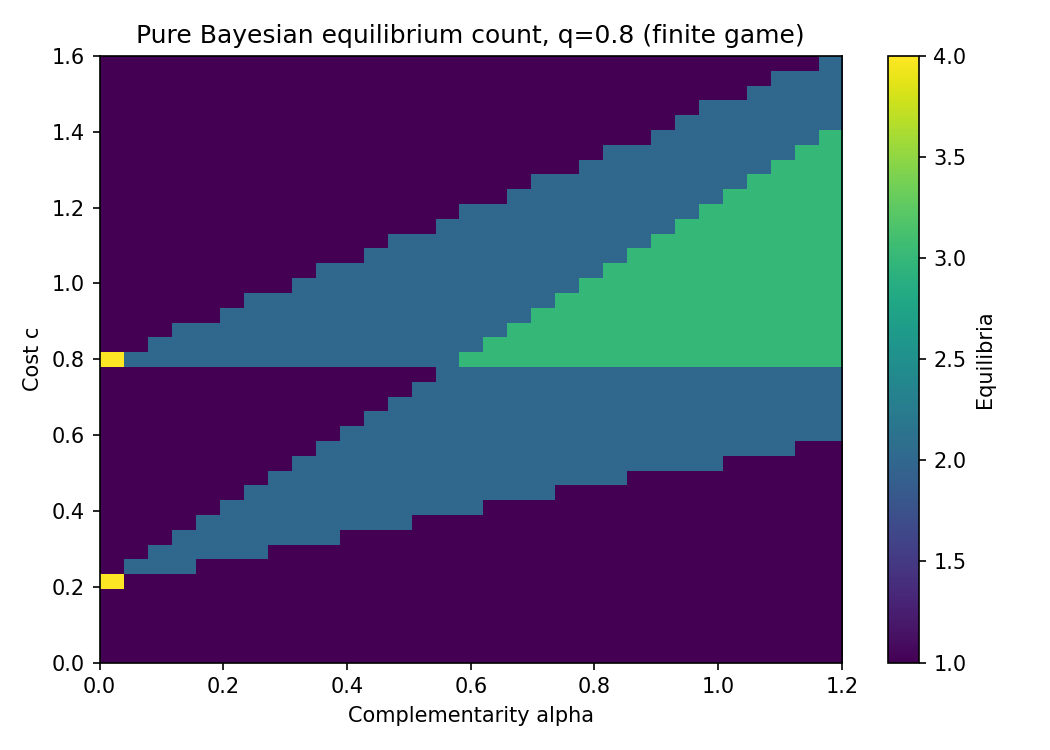

In [2]:
from IPython.display import Image, display
display(Image(filename='results/equilibria.png'))

In [3]:
print(Path('results/coverage.txt').read_text())

Name              Stmts   Miss Branch BrPart  Cover   Missing
-------------------------------------------------------------
src/__init__.py       0      0      0      0   100%
src/game.py          85      0     30      0   100%
-------------------------------------------------------------
TOTAL                85      0     30      0   100%



## Desarrollo semanal: mecanismo, sensibilidad y controles

Las celdas nuevas recalculan experimentos específicos. Las salidas históricas anteriores se conservan como evidencia separada y no sustituyen esta ejecución.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False})
SEED=20261018


### Del payoff a la decisión condicional
Con posterior $p_s=P(\theta=1\mid s)$, la ganancia de prestar es $p_s+\alpha E[a_j\mid s]-c$. Las políticas (0,0), (0,1), (1,0), (1,1) permiten enumerar 16 perfiles. Un perfil es BNE si ninguna desviación por tipo mejora su payoff; no basta con una condición agregada.

In [5]:
from src.game import Game,equilibria,exact_equilibria,regret,posterior,gain
from itertools import product
rows_new=[]
for q in [.55,.7,.85,.95]:
    for cost in np.linspace(.1,1.7,25):
        g=Game(accuracy=q,cost=float(cost),complementarity=.8)
        points=equilibria(g)
        assert set(points)==set(exact_equilibria(g))
        assert all(regret(g,p)<=1e-12 for p in points)
        lending=[sum(p[0]+p[1])/4 for p in points]
        rows_new.append(dict(accuracy=q,cost=cost,equilibria=len(points),
            min_policy_lending=min(lending) if lending else np.nan,max_policy_lending=max(lending) if lending else np.nan))
bne_table=pd.DataFrame(rows_new);display(bne_table.groupby('accuracy').agg(min_BNE=('equilibria','min'),max_BNE=('equilibria','max')))


,min_BNE,max_BNE
accuracy,,
0.55,1,3
0.70,1,3
0.85,1,3
0.95,1,2


### Frontera de coordinación
El mapa cuenta sólo equilibrios puros. Cero equilibrios puros no demostraría inexistencia de mixtos. La media de las cuatro acciones contingentes no es una tasa de préstamo observada; se usa sólo para describir políticas.

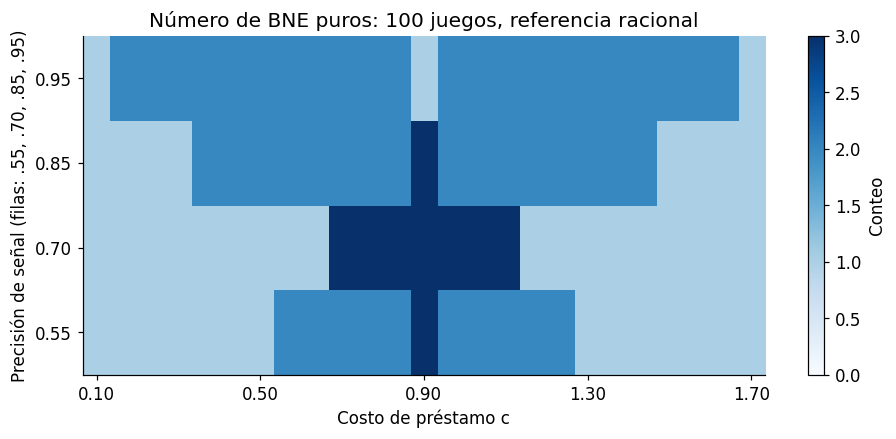

,señal,posterior,ganancia si otro no presta,ganancia si otro presta
0,0,0.2,-0.7,0.1
1,1,0.8,-0.1,0.7


In [6]:
pivot=bne_table.pivot(index='accuracy',columns='cost',values='equilibria')
fig,ax=plt.subplots(figsize=(10,4))
im=ax.imshow(pivot.to_numpy(),origin='lower',aspect='auto',cmap='Blues',vmin=0)
ax.set_xticks([0,6,12,18,24],[f'{v:.2f}' for v in pivot.columns[[0,6,12,18,24]]])
ax.set_yticks(range(len(pivot)),[f'{q:.2f}' for q in pivot.index])
ax.set(xlabel='Costo de préstamo c',ylabel='Precisión de señal (filas: .55, .70, .85, .95)',title='Número de BNE puros: 100 juegos, referencia racional')
fig.colorbar(im,ax=ax,label='Conteo');plt.show()
# Posterior and incentive check in a fully specified central game.
g=Game();display(pd.DataFrame([{'señal':s,'posterior':posterior(g,s),'ganancia si otro no presta':gain(g,s,(0,0)),
    'ganancia si otro presta':gain(g,s,(1,1))} for s in [0,1]]))

### Qué cambia la conclusión
El contraste racional controla errores de redondeo en este corpus; la multiplicidad requiere una regla de selección antes de convertir equilibrios en una predicción. Más precisión de señales no elimina por sí sola complementariedad estratégica. El supuesto de independencia condicional se debe contrastar en una aplicación.